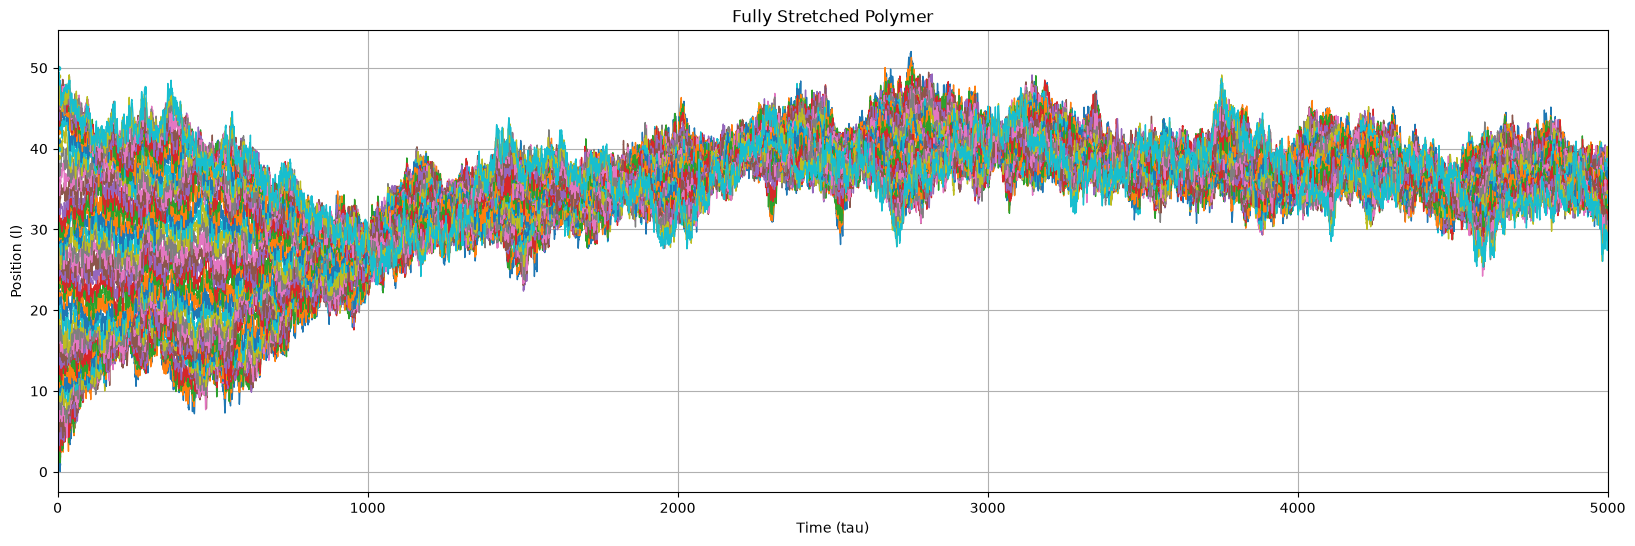

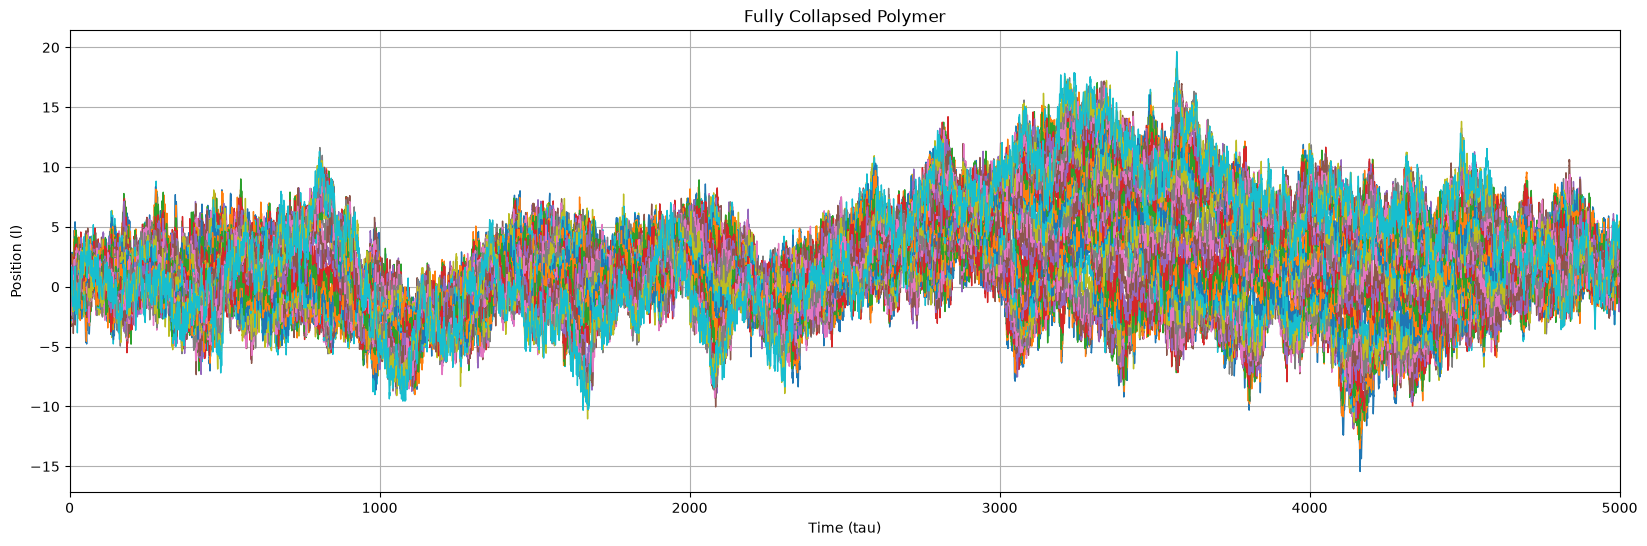

In [13]:
"""
Task (a)

1. Simulate the motion of a chain of length N = 50 over a time span of 5000 tau for a fully stretched and a
    fully collapsed polymer;
2. Plot the radius of gyration Rg and the end to end distance Re as a function of time;
3. Plot the potential energy per particle as a function of time.

"""

import numpy as np
import matplotlib.pyplot as plt

"""
Task a1: Simulate the motion of a chain of length N = 50 over a time span of 5000 tau for a fully stretched 
        and a fully collapsed polymer;
"""

# Define the parameters

k = 1
m = 1
l = 1
epsilon = k * l**2                                      # Energy unit for the harmonic chain
tau = np.sqrt(m / k)                                    # Time unit for the harmonic chain

N = 50                                                  # Number of beads in the chain
t = 5000                                                # Total time in tau
dt = 0.01                                               # Time step in tau
n = int(round(t / dt))                                  # Number of time steps

x0_stretch = np.array([i for i in range (1, N+1)])      # Initial position of the fully stretched polymer
x0_collapse = np.zeros(N)                               # Initial position of the fully collapsed polymer



# Define the force functions

def F_1(x1, x2):
    # force function for the first particle
    return k * (x2 - x1)

def F_i(x1, x2, x3):
    # force function for intermediate particles
    return k * (x1 - 2 * x2 + x3)

def F_N(x1, x2):
    # force function for the last particle
    return k * (x1 - x2)



# Define the Verlet integration function

def verlet(x_0, N, t, dt):
    # Molecular dynamics simulation using Velocity-Verlet algorithm

    # x_0 (array): initial positions of particles
    # p_0 (array): initial momenta of particles
    # N (int): number of particles
    # t (float): total simulation time
    # dt (float): time step

    n = int(round(t / dt))                                          # Number of time steps
    x = np.zeros((N, n + 1))                                        # Array to store positions of particles at each time step
    p = np.zeros((N, n + 1))                                        # Array to store momenta of particles at each time step
    p_ = np.zeros((N, n + 1))                                       # Array to store half-step momenta
    steps_per_tau = int(round(tau / dt))                            # Number of steps per tau
    x[:, 0] = x_0                                                   # Set initial positions

   
    for j in range(n):
        # for each time step

        if j % steps_per_tau == 0:
            # Random momentum kick every tau
            p[:, j] = np.random.normal(
                0, np.sqrt(m * epsilon), N
            )
            p_[:, j] = p[:, j]

        for i in range(N):
            # for each particle
            if i == 0:
                F = F_1(x[i, j], x[i + 1, j])                                   # Force on the first particle

            elif i == N - 1:
                F = F_N(x[i - 1, j], x[i, j])                                   # Force on the last particle

            else:
                F = F_i(x[i - 1, j], x[i, j], x[i + 1, j])                      # Force on intermediate particles

            p_[i, j + 1] = p[i, j] + 0.5 * dt * F                               # Update momentum at half step
            x[i, j + 1] = x[i, j] + dt * p_[i, j + 1] / m                       # Update position

        for i in range(N):
            # for each particle
            
            if i == 0:      
                F_whole = F_1(x[i, j + 1], x[i + 1, j + 1])                     # Calculate newforce for the first particle

            elif i == N - 1:
                F_whole = F_N(x[i - 1, j + 1], x[i, j + 1])                     # Calculate new force for the last particle
            
            else:
                F_whole = F_i(x[i - 1, j + 1], x[i, j + 1], x[i + 1, j + 1])    # Calculate new force for intermediate particles
            
            p[i, j + 1] = p_[i, j + 1] + 0.5 * dt * F_whole                     # Update momentum at full step
                    

    return x, p                                                                 # Return arrays of positions, momenta, and end-to-end distances



# Define the matplotlib function

def plot_x(x, t, dt, title):
    # Plot the positions of the particles over time

    n = int(round(t / dt))                                          # Number of time steps
    time = np.linspace(0, t, n + 1)                                 # Time array

    plt.figure(figsize=(20, 6))
    for i in range(x.shape[0]):
        line, = plt.plot(time, x[i, :], label=f'Particle {i + 1}', linewidth=1)             # Plot positions of each particle over time
        plt.plot(time[0], x[i, 0], 'o', color=line.get_color(), markersize=3)               # Plot initial positions as dots

    plt.xlim(0, t)
    plt.title(title)
    plt.xlabel('Time (tau)')
    plt.ylabel('Position (l)')
    plt.grid()
    plt.show()



# Run the simulation for the fully stretched polymer
x_stretch, p_stretch = verlet(x0_stretch, N, t, dt)
plot_x(x_stretch, t, dt, 'Fully Stretched Polymer')

# Run the simulation for the fully collapsed polymer
x_collapse, p_collapse = verlet(x0_collapse, N, t, dt)
plot_x(x_collapse, t, dt, 'Fully Collapsed Polymer')


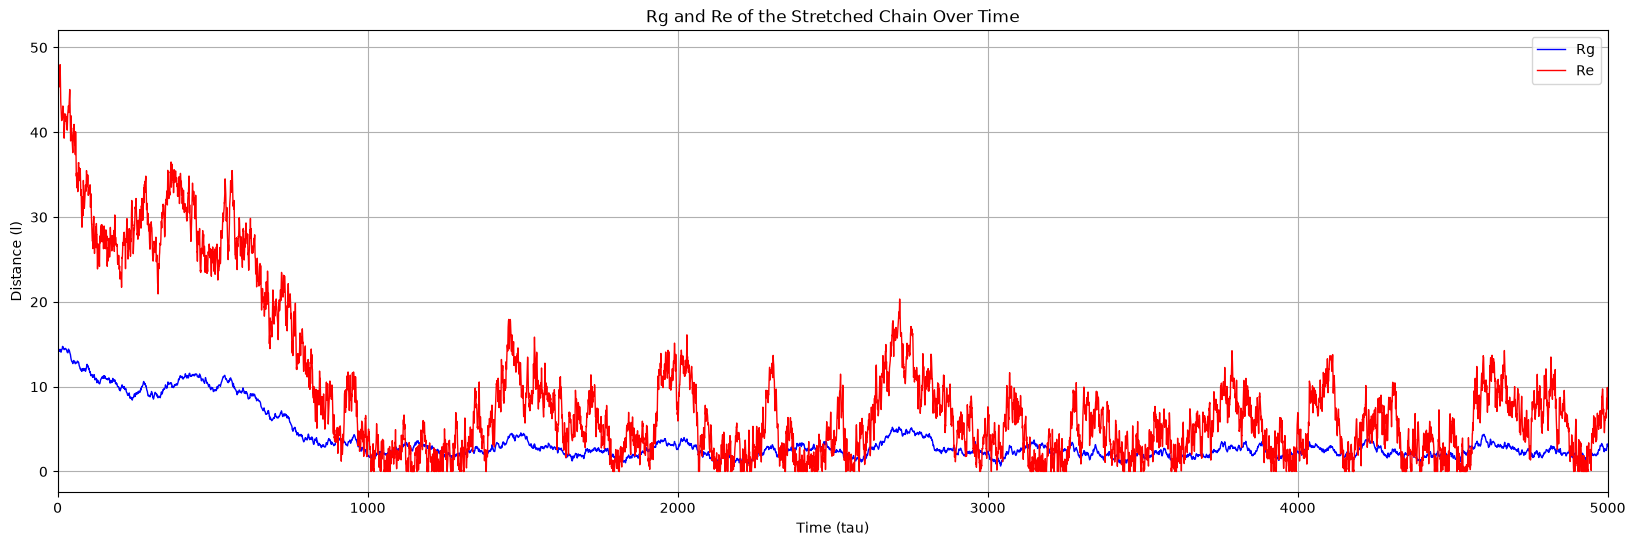

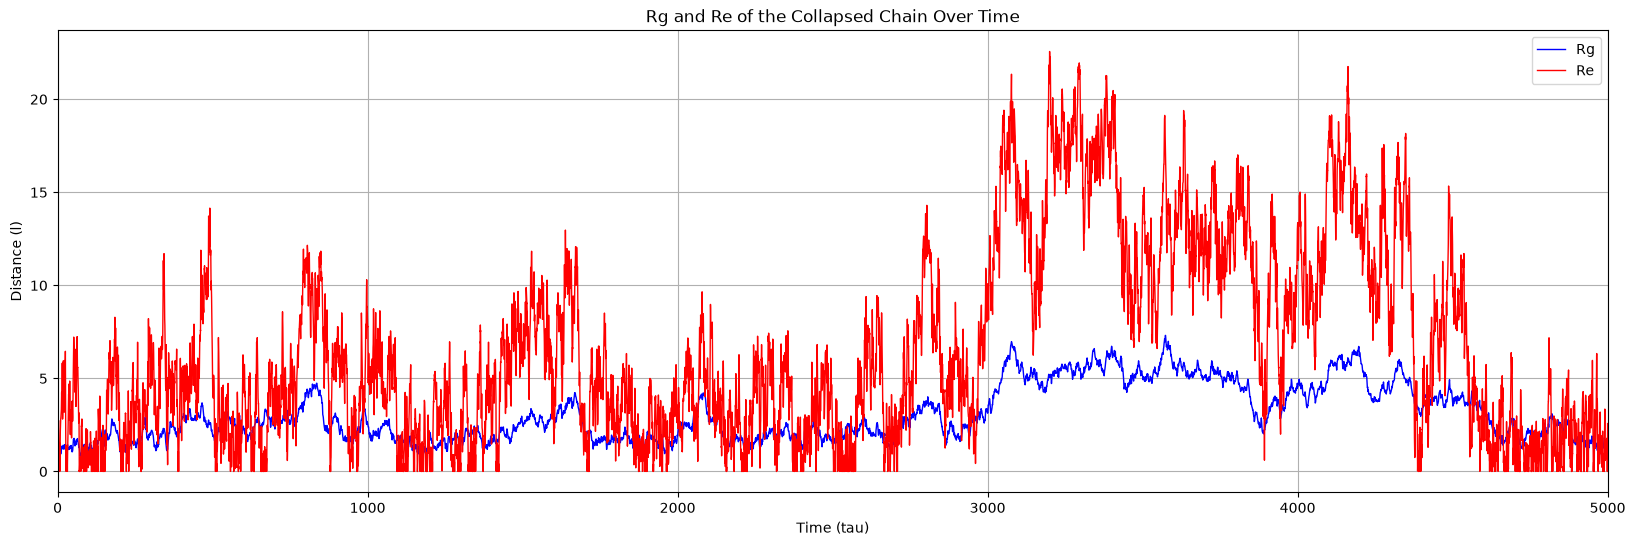

In [14]:
"""
Task a2: Plot the radius of gyration Rg and the end to end distance Re as a function of time;
"""

# Define the function to calculate the radius of gyration

def Rg(x):
    # Calculate the radius of gyration of the chain

    # x (array): positions of particles

    N, n_ = x.shape
    Rg = np.zeros(n_)                                             # Array to store the radius of gyration

    for j in range(n_):
        Rg[j] = np.sqrt(np.sum((x[:, j] - np.mean(x[:, j]))**2) / N)  # Calculate radius of gyration at each time step

    return Rg                                                     # Return the array of radius of gyration



# Define the function to calculate the end-to-end distance

def Re(x):
    # Calculate the end-to-end distance of the chain

    # x (array): positions of particles

    N, n_ = x.shape
    Re = np.zeros(n_)                                                # Array to store the end-to-end distance

    for j in range(n_):
        Re[j] = np.linalg.norm(x[N-1, j] - x[0, j])                  # Calculate end-to-end distance at each time step

    return Re                                                        # Return the array of end-to-end distances



# Define the function to plot Rg and Re

def plot_R(Rg, Re, t, dt, title):
    # Plot the end-to-end distance of the chain over time

    # Rg, Re (array): matrix to plot
    # dt (integer): time step in unit tau
    # title (string): name of the plot
    

    time = np.arange(len(Rg)) * dt                                   # Time array

    plt.figure(figsize=(20, 6))
    plt.plot(time, Rg, label='Rg', color='blue', linewidth=1)        # Plot radius of gyration over time
    plt.plot(time, Re, label='Re', color='red', linewidth=1)         # Plot end-to-end distance over time

    plt.xlim(0, t)
    plt.title(title)
    plt.xlabel('Time (tau)')
    plt.ylabel('Distance (l)')
    plt.legend()
    plt.grid()
    plt.show()



# Run the simulation for the fully stretched polymer

plot_R(Rg(x_stretch), Re(x_stretch), t, dt, 'Rg and Re of the Stretched Chain Over Time')


# Run the simulation for the fully collapsed polymer

plot_R(Rg(x_collapse), Re(x_collapse), t, dt, 'Rg and Re of the Collapsed Chain Over Time')


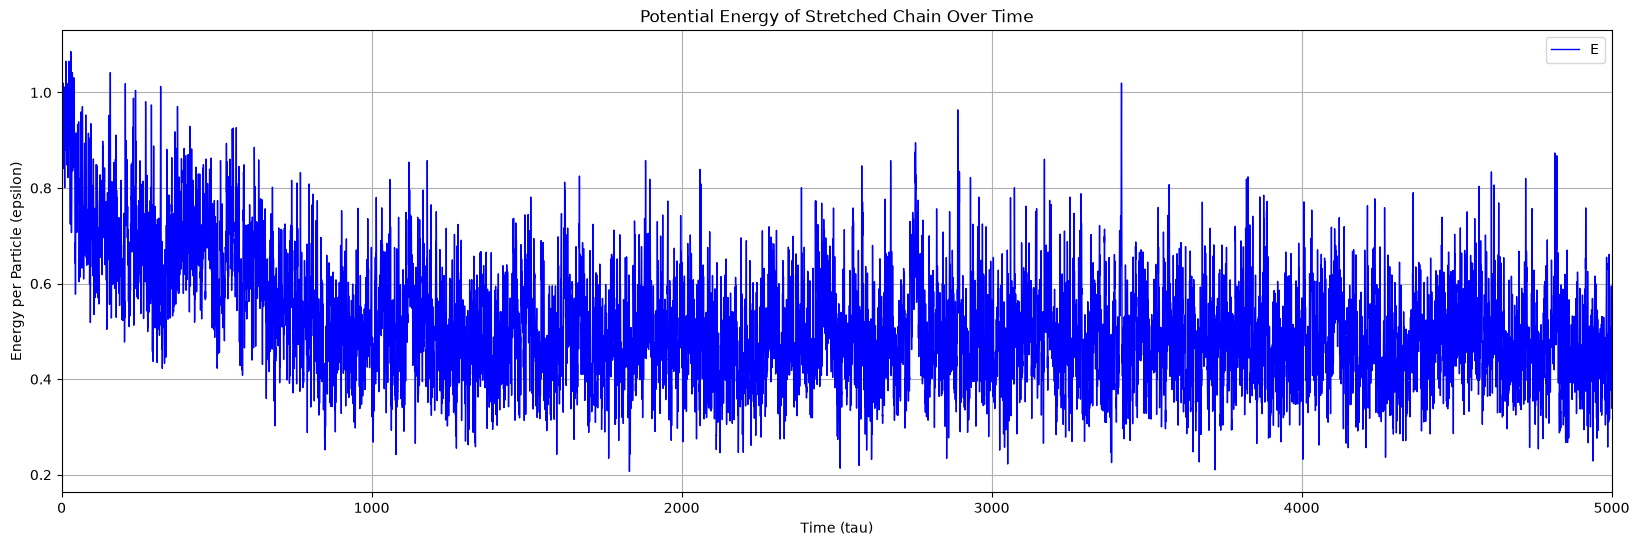

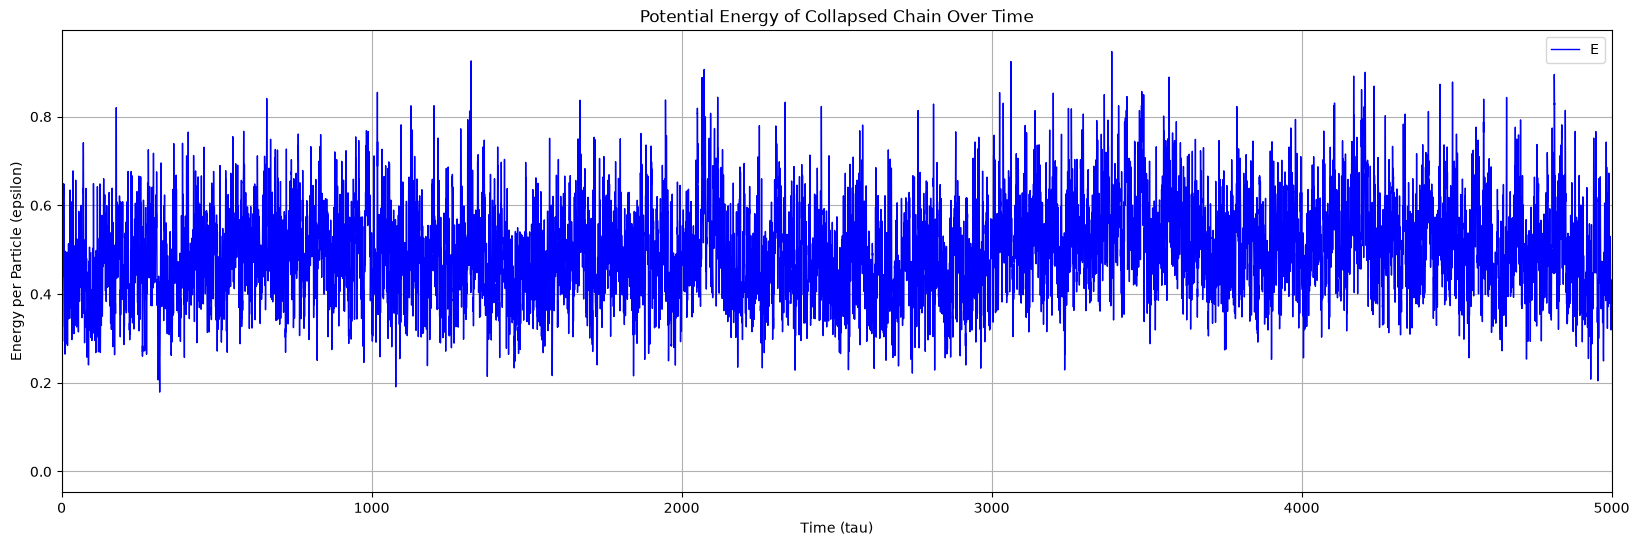

In [15]:
"""
Task a3: Plot the potential energy per particle as a function of time.
"""

# Define the function to calculate the potential energy

def E_pot(x, k):

    # x (array): position matrix of the polymer chain
    # k (float): spring constant

    N, n_ = x.shape
    E = np.zeros(n_)                                                 # Array to store the energy

    for j in range(n_):
        E[j] = np.sum(k / 2 * (x[1:, j] - x[:-1, j]) ** 2)

    return E



# Define the function to plot E

def plot_E(E, t, dt, title):
    # Plot the end-to-end distance of the chain over time

    # E (array): matrix to plot
    # dt (integer): time step in unit tau
    # title (string): name of the plot
    

    time = np.arange(len(E)) * dt                                    # Time array

    plt.figure(figsize=(20, 6))
    plt.plot(time, E, label='E', color='blue', linewidth=1)          # Plot energy

    plt.xlim(0, t)
    plt.title(title)
    plt.xlabel('Time (tau)')
    plt.ylabel('Energy per Particle (epsilon)')
    plt.legend()
    plt.grid()
    plt.show()



# Calculate and plot the energy of polymer chain

plot_E(E_pot(x_stretch, 1)/N, t, dt, 'Potential Energy of Stretched Chain Over Time')
plot_E(E_pot(x_collapse, 1)/N, t, dt, 'Potential Energy of Collapsed Chain Over Time')


In [16]:
"""
Task (b)
1. Compute the average Rg squared and Re squared in equilibrium;
2. Compute the time averege internal energy per particle U/N;
3. Repeat the calculation 4 times using random seeds, and compute the time average;
4. Determine the statistical uncertainties.
"""

"""
Task b1: Compute the average Rg squared and Re squared in equilibrium;
"""

# Define the function to calculate the mean Rg squared

def Rg_sqr(x):
    # Calculate the mean Rg squared of the chain

    # x (array): 2D positions of particles

    N, n_ = x.shape
    Rg = np.zeros(n_)                                                   # Array to store the radius of gyration


    for j in range(n_):
        Rg[j] = np.mean((x[:, j] - np.mean(x[:, j]))**2)                # Calculate radius of gyration at each time step

    return Rg                                                           # Return the array of radius of gyration



# Define the function to calculate the end-to-end distance

def Re_sqr(x):
    # Calculate the end-to-end distance of the chain

    # x (array): 2D positions of particles

    N, n_ = x.shape
    Re = np.zeros(n_)                                                   # Array to store the end-to-end distance

    for j in range(n_):
        Re[j] = (x[N-1, j] - x[0, j]) ** 2                              # Calculate end-to-end distance at each time step

    return Re                                                           # Return the array of end-to-end distances



# calculate time average

Rg_avg_stretch = np.zeros(5)                                            # Create empty list to store the time average values
Re_avg_stretch = np.zeros(5)
Rg_avg_collapse = np.zeros(5)
Re_avg_collapse = np.zeros(5)

Rg_avg_stretch[0] = np.mean(Rg_sqr(x_stretch)[500:])                    # Calculate the time avereage
Re_avg_stretch[0] = np.mean(Re_sqr(x_stretch)[500:])
Rg_avg_collapse[0] = np.mean(Rg_sqr(x_collapse)[100:])
Re_avg_collapse[0] = np.mean(Re_sqr(x_collapse)[100:])


In [17]:
"""
Task b2: Compute the time averege internal energy per particle U/N;
"""

# Create function to calculate internal energy

def E_int(x, p, k, m):
    # Calculate the internal energy

    # x (array): 2D positions of particles
    # p (array): 2D momentums of particles
    # k (float): spring constant
    # m (float): mass of particles

    N, n_ = p.shape
    E_kin = np.zeros(n_)                                      # Array to store the kinetic energy
    E_int = np.zeros(n_)                                      # Array to store the internal energy
    
    for i in range(n_):
        E_kin[i] = np.sum(p[:, i] ** 2 / (2*m))

    E_pot_ = E_pot(x, k)
    E_int = E_pot_ + E_kin

    return E_int

E_int_avg_stretch = np.zeros(5)
E_int_avg_collapse = np.zeros(5)

E_int_avg_stretch[0] = np.mean((E_int(x_stretch, p_stretch, k, m)/N)[500:])
E_int_avg_collapse[0] = np.mean((E_int(x_collapse, p_collapse, k, m)/N)[100:])



In [18]:
"""
Task b3: Repeat the calculation 4 times using random seeds, and compute the time average;
"""

for i in range(1, 5):
    x_stretch_, p_stretch_ = verlet(x0_stretch, N, t, dt)           # Run a new simulation of random seeds
    x_collapse_, p_collapse_ = verlet(x0_collapse, N, t, dt)

    Rg_avg_stretch[i] = np.mean(Rg_sqr(x_stretch_)[500:])           # Calculate time avereage
    Rg_avg_collapse[i] = np.mean(Rg_sqr(x_collapse_)[100:])

    Re_avg_stretch[i] = np.mean(Re_sqr(x_stretch_)[500:])
    Re_avg_collapse[i] = np.mean(Re_sqr(x_collapse_)[100:])

    E_int_avg_stretch[i] = np.mean((E_int(x_stretch_, p_stretch_, k, m)/N)[500:])
    E_int_avg_collapse[i] = np.mean((E_int(x_collapse_, p_collapse_, k, m)/N)[100:])




In [19]:
"""
Task b4: Determine the statistical uncertainties.
"""

dic_s = {}                                                        # Dictionaries to store the values
dic_c = {}


dic_s['mean Rg'] = np.mean(Rg_avg_stretch)                                     # Mean values of 5 simulations
dic_c['mean Rg'] = np.mean(Rg_avg_collapse)

dic_s['mean Re'] = np.mean(Re_avg_stretch)
dic_c['mean Re'] = np.mean(Re_avg_collapse)

dic_s['mean internal E'] = np.mean(E_int_avg_stretch)
dic_c['mean internal E'] = np.mean(E_int_avg_collapse)


dic_s['Rg SD'] = np.sqrt((np.sum((Rg_avg_stretch - dic_s['mean Rg'])**2))/len(Rg_avg_stretch))      # Standard deviation
dic_c['Rg SD'] = np.sqrt((np.sum((Rg_avg_collapse - dic_c['mean Rg'])**2))/len(Rg_avg_collapse))

dic_s['Re SD'] = np.sqrt((np.sum((Re_avg_stretch - dic_s['mean Re'])**2))/len(Re_avg_stretch))
dic_c['Re SD'] = np.sqrt((np.sum((Re_avg_collapse - dic_c['mean Re'])**2))/len(Re_avg_collapse))

dic_s['E SD'] = np.sqrt((np.sum((E_int_avg_stretch - dic_s['mean internal E'])**2))/len(E_int_avg_stretch))
dic_c['E SD'] = np.sqrt((np.sum((E_int_avg_collapse - dic_c['mean internal E'])**2))/len(E_int_avg_collapse))


dic_s['Rg SEM'] = dic_s['Rg SD'] / np.sqrt(N)                                  # Standar error of mean
dic_c['Rg SEM'] = dic_c['Rg SD'] / np.sqrt(N)

dic_s['Re SEM'] = dic_s['Re SD'] / np.sqrt(N)
dic_c['Re SEM'] = dic_c['Re SD'] / np.sqrt(N)

dic_s['E SEM'] = dic_s['E SD'] / np.sqrt(N)
dic_c['E SEM'] = dic_c['E SD'] / np.sqrt(N)


print("For fully stretched polymer,\n", dic_s)
print("For fully collapsed polymer,\n", dic_c)

For fully stretched polymer,
 {'mean Rg': np.float64(23.930818382542448), 'mean Re': np.float64(178.0112205068319), 'mean internal E': np.float64(1.0231752625872426), 'Rg SD': np.float64(8.116457428000011), 'Re SD': np.float64(60.778384886294646), 'E SD': np.float64(0.017465465447554045), 'Rg SEM': np.float64(1.1478404173101464), 'Re SEM': np.float64(8.595361620532982), 'E SEM': np.float64(0.0024699898109089608)}
For fully collapsed polymer,
 {'mean Rg': np.float64(8.562852892671964), 'mean Re': np.float64(49.47542367016427), 'mean internal E': np.float64(0.9913512777928781), 'Rg SD': np.float64(1.69109300153686), 'Re SD': np.float64(11.73633581684719), 'E SD': np.float64(0.004069990106453717), 'Rg SEM': np.float64(0.23915666580076525), 'Re SEM': np.float64(1.6597685284750412), 'E SEM': np.float64(0.0005755835207271163)}
